In [13]:
import pandas as pd
import numpy as np
reading_messy = pd.read_csv('aaus4_class_meter_readings_messy - aaus4_class_meter_readings_messy.csv')
treatment_messy = pd.read_csv('aaus4_class_treatment_samples_messy - aaus4_class_treatment_samples_messy.csv')
print(f"Meter Reading Messy Data Count {reading_messy.shape} and Treatment Messy Data Count {treatment_messy.shape}")
print(reading_messy.head(0).to_string())
print(treatment_messy.head(0).to_string())
print('curr dtype: ', str(reading_messy.curr_m3.dtypes))
print(reading_messy[['prev_m3','curr_m3']].isna().sum().to_dict())
#reading_messy.head(1)
#print(len(reading_messy))
#print(len(treatment_messy))
#treatment_messy.head(1)
#reading_messy.info
#treatment_messy.info

Meter Reading Messy Data Count (432, 11) and Treatment Messy Data Count (369, 11)
Empty DataFrame
Columns: [record_id, meter_id, read_date, branch, customer_segment, meter_type, prev_m3, curr_m3, status, source_system, collector_team]
Index: []
Empty DataFrame
Columns: [sample_id, sample_date, plant, district, sampling_point, treatment_type, chlorine_mg_l, turbidity_ntu, ph, analyst_team, result_status]
Index: []
curr dtype:  object
{'prev_m3': 0, 'curr_m3': 11}


In [14]:
s = pd.Series([12.0,None,18.8,24.0])
filled = s.fillna(s.median())
print(filled.tolist())
print('changed : ', int(s.isna().sum()))

[12.0, 18.8, 18.8, 24.0]
changed :  1


In [25]:
lab = treatment_messy.copy()
lab['chlorine_num'] = pd.to_numeric(lab.chlorine_mg_l,errors='coerce')
#lab['chlorine_fill'] = lab.groupby('plant')['chlorine_num'].transform(lamda x: x.fillna(x.median()))
#print('Remaining : ',int(lab.chlorine_fill.isna().sum()))

In [20]:
w = pd.read_csv('aaus4_class_maintenance_orders_messy - aaus4_class_maintenance_orders_messy.csv')
print("Length Od Data :", len(w))
print("Data Duplication : ", int(w.duplicated().sum()))

Length Od Data : 310
Data Duplication :  10


In [23]:
key_dup = w.duplicated(subset=['order_id'] , keep=False)
print('Raw With Repeted IDs : ' , int(key_dup.sum()))
print('Distinct Repitws ID ', w.loc[key_dup,'order_id'].nunique())

Raw With Repeted IDs :  20
Distinct Repitws ID  10


In [27]:
print(reading_messy[['prev_m3','curr_m3']]
.isna().sum().to_dict())
print('raw rows:', len(reading_messy))

{'prev_m3': 0, 'curr_m3': 11}
raw rows: 432


In [29]:
rates = (reading_messy.isna().mean()*100).round(1)
print(rates[rates>0].to_dict())

{'curr_m3': 2.5}


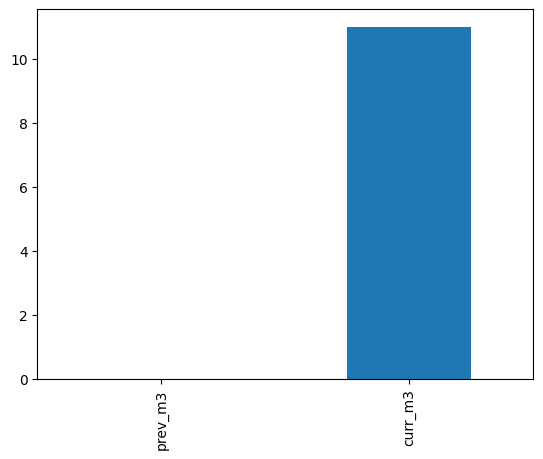

In [30]:
import matplotlib.pyplot as plt
reading_messy.isna().sum().loc[
  ['prev_m3','curr_m3']
].plot.bar()
plt.show()

In [33]:
m_required = reading_messy.dropna(subset=['curr_m3'])
print('before:', len(reading_messy))
print('after:', len(m_required))
print('dropped:', len(reading_messy)-len(m_required))

before: 432
after: 421
dropped: 11


In [34]:
ab = treatment_messy.copy()
lab['chlorine_num'] = pd.to_numeric(
lab.chlorine_mg_l, errors='coerce')
lab['chlorine_fill'] = lab.groupby('plant')[
'chlorine_num'].transform(
lambda x: x.fillna(x.median()))
print('remaining:', 
int(lab.chlorine_fill.isna().sum()))

remaining: 0


In [36]:
w = pd.read_csv('aaus4_class_maintenance_orders_messy - aaus4_class_maintenance_orders_messy.csv')
print('raw work orders:', len(w))
print('full duplicates:', int(w.duplicated().sum()))

raw work orders: 310
full duplicates: 10


In [37]:
key_dups = w.duplicated(subset=['order_id'], keep=False)
print('rows with repeated ID:', int(key_dups.sum()))
print('distinct repeated IDs:', w.loc[key_dups,
'order_id'].nunique())

rows with repeated ID: 20
distinct repeated IDs: 10


In [38]:
w_unique = w.drop_duplicates(
subset=['order_id'], keep='first').copy()
print('unique orders:', len(w_unique))
print('IDs unique:', w_unique.order_id.is_unique)

unique orders: 300
IDs unique: True


In [40]:
m_unique = reading_messy.drop_duplicates('record_id').copy()
m_unique['curr_num'] = pd.to_numeric(
m_unique.curr_m3, errors='coerce')
print('raw NA:', int(m_unique.curr_m3.isna().sum()))
print('coerced NA:', int(m_unique.curr_num.isna().sum()))

raw NA: 11
coerced NA: 19


In [41]:
w_unique['opened_dt'] = pd.to_datetime(
w_unique.opened_date, errors='coerce',
format='%Y-%m-%d')
print('invalid open dates:',
int(w_unique.opened_dt.isna().sum()))

invalid open dates: 5


In [42]:
priority = pd.Series(['1','2','bad','4'])
converted = pd.to_numeric(
priority, errors='coerce').astype('Int64')
print(converted.tolist())
print(str(converted.dtype))

[1, 2, <NA>, 4]
Int64


In [43]:
a = pd.read_csv('aaus4_class_asset_registry_messy.csv')
a['condition_clean'] = (
a.condition.str.strip().str.title())
print(a.condition_clean.value_counts()
.to_dict())

{'Critical': 51, 'Poor': 51, 'Fair': 43, 'Good': 43}
